# 02 - OU half-life and Kalman hedge ratios

Half-life = ln2/theta with theta = -ln(b)/dt, valid only for 0<b<1.  The Kalman innovation is computed from the PREDICTED state; the posterior residual uses y_t and is not a tradable z-score.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TAB, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("SYNTHETIC results demonstrate software behaviour; they are not market evidence.")

SYNTHETIC results demonstrate software behaviour; they are not market evidence.


In [2]:
from pairs import data as D
from pairs.ou import fit_ou, hurst_exponent, variance_ratio_test
u = D.simulate_ar1(2000, 10.0, 0.05, np.random.default_rng(0))
f = fit_ou(u)
print(f.status, round(f.b, 4), 'half-life', round(f.half_life, 2), 'CI', tuple(round(v, 1) for v in f.half_life_ci))
print('Hurst', hurst_exponent(u), '\nVR', variance_ratio_test(u, 5))
print('negative b ->', fit_ou(-0.5*np.ones(50) + np.random.default_rng(1).normal(0, 1, 50)).status)

ok 0.9348 half-life 10.27 CI (8.2, 13.6)
Hurst {'hurst': 0.3542795200622015, 'r2': 0.9811774849268455, 'min_lag': 2, 'max_lag': 20} 
VR {'vr': 0.8737532890760362, 'z_hom': -2.5763558649693983, 'z_het': -2.61570042323308, 'p_hom': 0.009984782437415903, 'p_het': 0.00890446449549025, 'q': 5, 'n': 1999}
negative b -> ok


delta 1e-05 max |ours - pykalman| 2.0294876890147862e-13


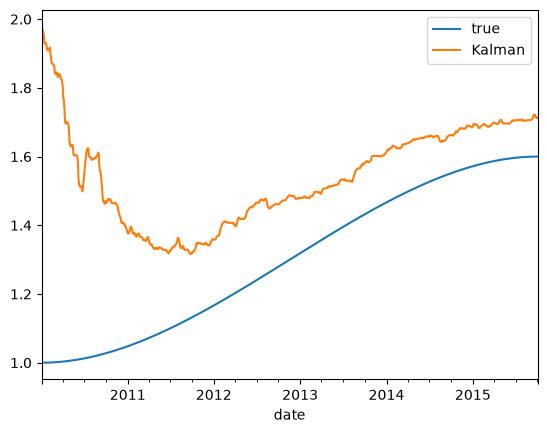

In [3]:
from pairs.hedge import tune_kalman, kalman_filter, pykalman_reference
df, _ = D.time_varying_beta_pair(1500, seed=3)
t = tune_kalman(df.y[:400], df.x[:400], [1e-7, 1e-6, 1e-5, 1e-4])
kf, ll = kalman_filter(df.y, df.x, t.Q, t.R, np.array(t.m0), np.diag(t.P0_diag))
ref = pykalman_reference(df.y, df.x, t.Q, t.R, np.array(t.m0), np.diag(t.P0_diag))
print('delta', t.delta, 'max |ours - pykalman|', None if ref is None else float(np.abs(ref.values - kf[['alpha','beta']].values).max()))
ax = df.beta_true.plot(label='true'); kf.beta.plot(ax=ax, label='Kalman'); ax.legend(); plt.show()

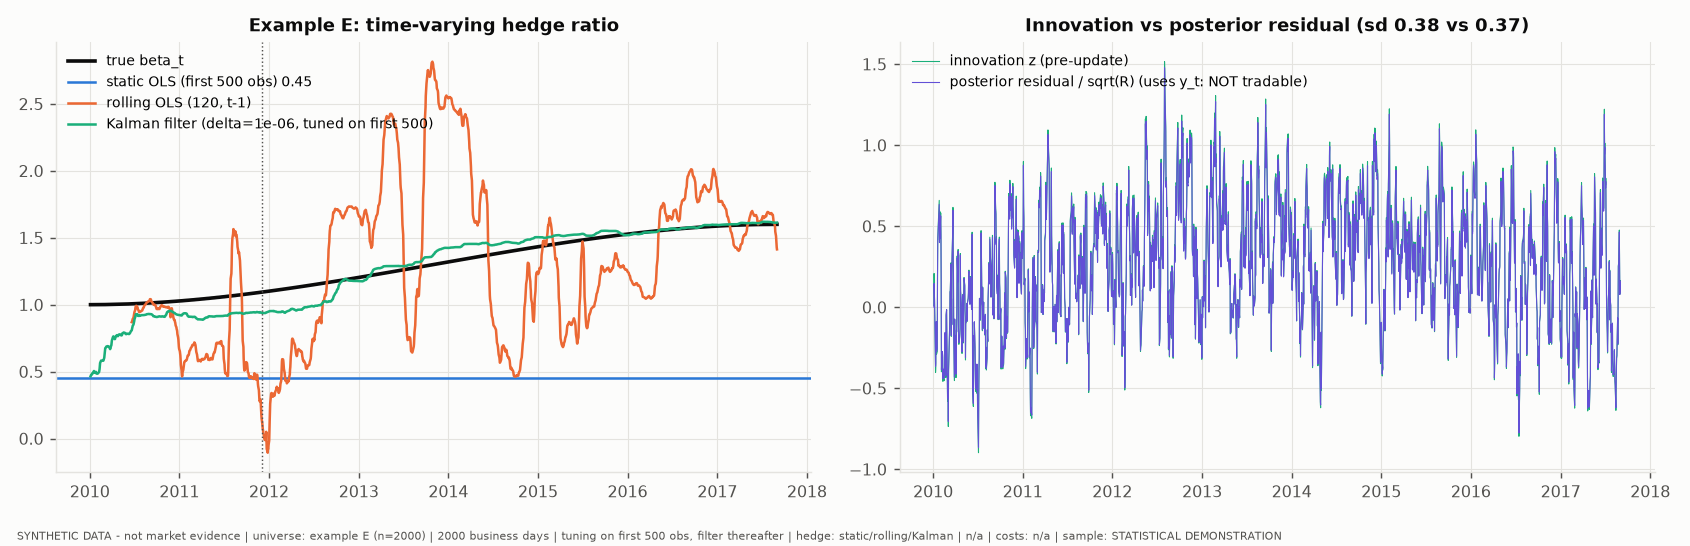

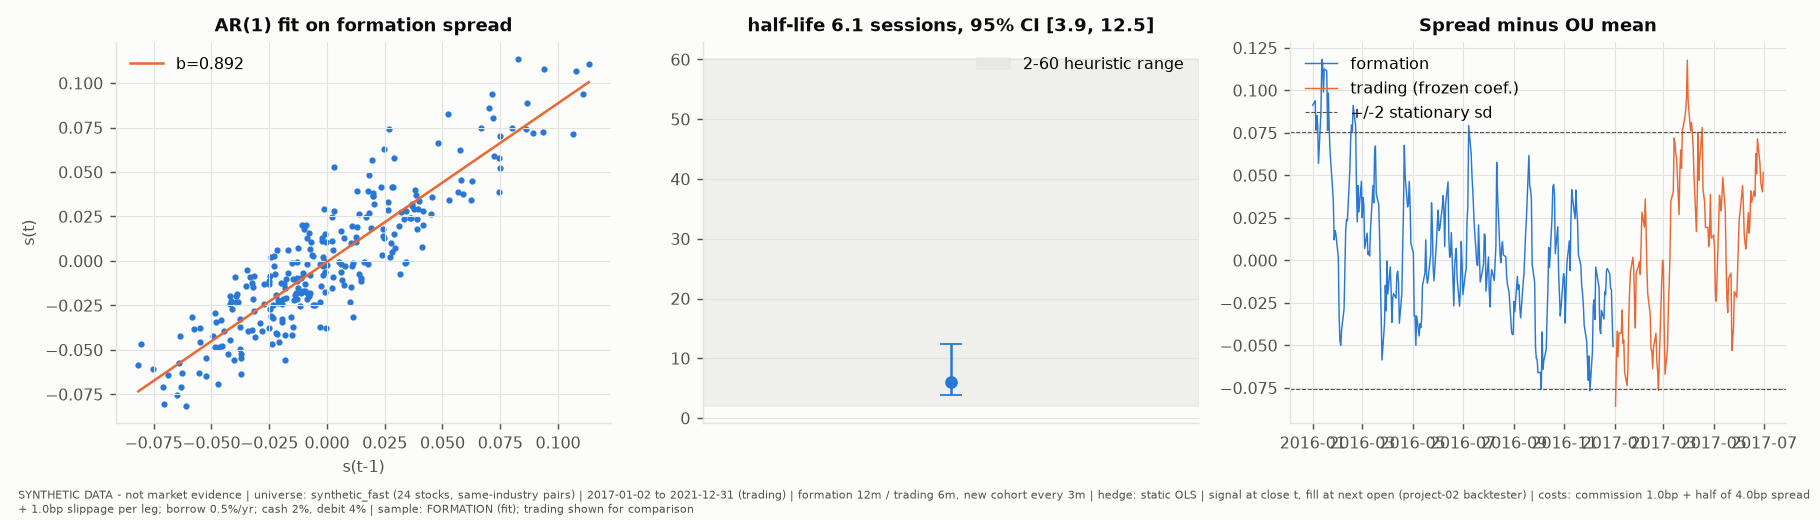

In [4]:
display(Image(FIG / 'syn_05b_kalman_time_varying_beta.png'))
display(Image(FIG / 'syn_06_ou_fit_half_life.png'))

In [5]:
display(pd.read_csv(TAB / 'syn_14b_oos_spread_adf_by_method.csv').groupby('method').adf_p_nominal.median())
print('Adaptive (rolling/Kalman) residuals look more stationary by construction: nominal ADF p-values are not valid inference for them.')

method
kalman         0.000848
rolling_ols    0.073935
static_ols     0.190222
Name: adf_p_nominal, dtype: float64

Adaptive (rolling/Kalman) residuals look more stationary by construction: nominal ADF p-values are not valid inference for them.
